# 07 — Reporte semanal para el comité

**Capa 4 — Salidas** y **Capa 5 — Consumo**

**Objetivo:** mostrar paso a paso cómo se arma el Excel que recibe el comité cada lunes: `outputs/reporte_radar_AAAA-MM-DD.xlsx`, donde la fecha es el cierre semanal de los datos.

En la operación normal, el reporte no se arma desde este notebook: lo genera `src/main.py` con un solo comando, junto con la ingesta, la validación y el semáforo. Este notebook usa las mismas funciones (`src/reporte.py`) para explicar qué hace cada una.

**Entradas:** `data/processed/panel_semanal.csv` y `data/processed/semaforo_actual.csv` (salidas de `src/features.py`).
**Salida:** el Excel con cuatro hojas: **Semáforo**, **Variables**, **Gráficos** y **Registro de revisión**.

In [1]:
import sys
from pathlib import Path

import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(RAIZ))

from src import config as C
from src import reporte as R

plt.rcParams.update({
    "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb",
    "axes.edgecolor": "#c3c2b7", "axes.labelcolor": "#52514e",
    "xtick.color": "#898781", "ytick.color": "#898781",
    "axes.grid": True, "grid.color": "#e1e0d9", "grid.linewidth": 0.6,
    "axes.spines.top": False, "axes.spines.right": False,
    "font.size": 10, "axes.titlesize": 11, "axes.titleweight": "bold",
})
pd.set_option("display.width", 200)
pd.set_option("display.max_colwidth", 200)

panel = pd.read_csv(C.DIR_PROCESSED / "panel_semanal.csv", parse_dates=["fecha"])
actual = pd.read_csv(C.DIR_PROCESSED / "semaforo_actual.csv", parse_dates=["fecha"])
fecha_datos = actual["fecha"].max()
print(f"Datos al cierre del viernes {fecha_datos:%d-%m-%Y} | {len(actual)} tickers")

Datos al cierre del viernes 30-10-2026 | 11 tickers


## 1. Hoja "Semáforo"

Es lo primero que ve el comité:
- **Encabezado:** título, fecha de los datos y fuente.
- **Nota de interpretación:** qué significa cada color y qué *no* dice el test (no predice la fecha de una caída).
- **Tabla:** ordenada por gravedad (rojo → amarillo → verde) y, dentro de cada color, por BSADF. La celda del color va pintada.

Columnas:
| Columna | Qué es |
|---|---|
| Color | Semáforo vigente (con persistencia de 6 semanas) |
| Semanas en el color | Cuántas semanas seguidas lleva en ese color |
| BSADF esta semana | Estadístico de la semana: más alto = crecimiento más explosivo |
| Umbral amarillo / rojo | Valores críticos al 90% y 95% (iguales para todos) |
| Señal bruta de la semana | Color que daría el BSADF de esta semana sin persistencia: anticipa posibles cambios |

In [2]:
print(R.NOTA_INTERPRETACION, "\n")
pd.DataFrame({
    "Ticker": actual["ticker"], "Nombre": actual["ticker"].map(R.nombre), "Color": actual["semaforo"],
    "Semanas en el color": actual["semanas_en_estado"], "BSADF esta semana": actual["bsadf"].round(2),
    "Umbral amarillo": actual["cv_bsadf_90"].round(2), "Umbral rojo": actual["cv_bsadf_95"].round(2),
    "Señal bruta": actual["semaforo_bruto"],
}).set_index("Ticker")

Cómo leer el semáforo: el test BSADF busca, en los últimos 5 años de cada acción, el tramo con el crecimiento más explosivo (un precio que sube porque ya subió). ROJO = evidencia fuerte de burbuja (supera el valor crítico al 95%): revisar reducir o cubrir la exposición. AMARILLO = señal temprana (supera el 90%): monitorear. VERDE = sin evidencia. Un color cambia solo si la señal se mantiene 6 semanas seguidas. El test detecta crecimiento explosivo, no predice la fecha de una caída. 



,Nombre,Color,Semanas en el color,BSADF esta semana,Umbral amarillo,Umbral rojo,Señal bruta
Ticker,,,,,,,
TSM,Taiwan Semiconductor,rojo,23,0.40,0.36,0.69,amarillo
AMD,Advanced Micro Devices,amarillo,11,0.01,0.36,0.69,verde
^GSPC,S&P 500,verde,451,0.09,0.36,0.69,verde
^IXIC,Nasdaq Composite,verde,653,-0.06,0.36,0.69,verde
NVDA,NVIDIA,verde,87,-0.21,0.36,0.69,verde
GOOGL,Alphabet,verde,4,-0.29,0.36,0.69,verde
AVGO,Broadcom,verde,38,-0.46,0.36,0.69,verde
META,Meta Platforms,verde,128,-0.67,0.36,0.69,verde
MSFT,Microsoft,verde,24,-0.69,0.36,0.69,verde


## 2. Hoja "Variables": por qué cada acción está en su color

La función `R.explicar` arma una explicación en palabras simples con reglas fijas:
1. **Color y duración:** "lleva N semanas en rojo/amarillo/verde".
2. **Transición:** si la señal bruta de esta semana difiere del color vigente, avisa que el color cambiará solo si se mantiene 6 semanas.
3. **Contexto de riesgo**, solo cuando es llamativo: momentum de 12 meses sobre +50% o bajo −20%, volatilidad anual sobre 45%, beta sobre 1,5.

Así el comité no necesita interpretar el estadístico: lee una frase.

La hoja trae además la columna **"Perfil de riesgo"**, que viene del modelo K-Means del notebook 04 (`src/perfiles.py`). `main.py` la calcula con el modelo guardado en `data/processed/perfiles_kmeans.json` y la deja en `semaforo_actual.csv`. Es descriptiva: no cambia el color.

In [3]:
explicaciones = actual.assign(explicacion=actual.apply(R.explicar, axis=1))
for _, fila in explicaciones.iterrows():
    print(f"[{fila['semaforo'].upper():8}] {fila['ticker']:6} perfil: {fila['perfil_riesgo']:28} {fila['explicacion']}")

[ROJO    ] TSM    perfil: estable                      Crecimiento explosivo: lleva 23 semanas en rojo (entró al superar el umbral rojo de 0,69 durante 6 semanas seguidas). Esta semana el BSADF es 0,40 (nivel amarillo); el color cambia solo si ese nivel se mantiene 6 semanas seguidas.
[AMARILLO] AMD    perfil: explosivo-alcista            Señal temprana: lleva 11 semanas en amarillo (entró al superar el umbral amarillo de 0,36 durante 6 semanas seguidas). Esta semana el BSADF es 0,01 (nivel verde); el color cambia solo si ese nivel se mantiene 6 semanas seguidas. Contexto: subió 97% en 12 meses; volatilidad alta (63% anual); muy sensible al mercado (beta 1,9).
[VERDE   ] ^GSPC  perfil: estable                      Sin evidencia de burbuja: lleva 451 semanas en verde. BSADF esta semana: 0,09.
[VERDE   ] ^IXIC  perfil: estable                      Sin evidencia de burbuja: lleva 653 semanas en verde. BSADF esta semana: -0,06.
[VERDE   ] NVDA   perfil: estable                      Sin evi

## 3. Hoja "Gráficos"

Muestra la evolución del BSADF en los últimos 3 años de los tickers en **amarillo o rojo**, junto a los dos umbrales. Si ningún ticker está en alerta, muestra los 3 con mayor BSADF, para que el comité vea quién está más cerca. En el Excel es un gráfico nativo (editable); aquí se reproduce con matplotlib para revisarlo.

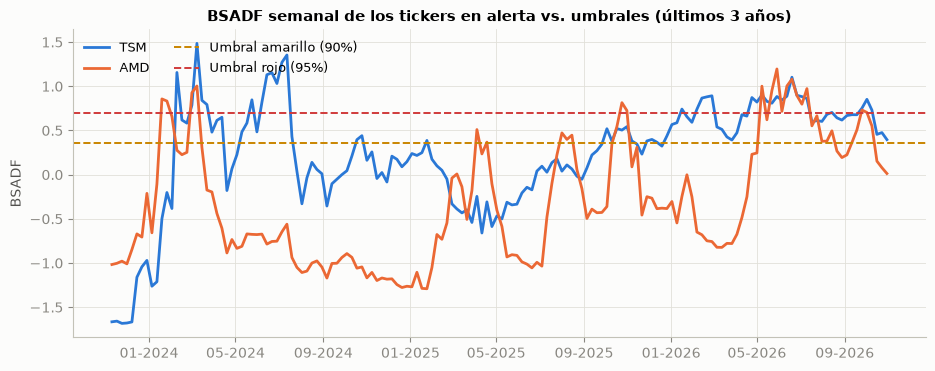

In [4]:
alerta = actual.loc[actual["semaforo"] != "verde", "ticker"].tolist()
seleccion = alerta or actual.nlargest(3, "bsadf")["ticker"].tolist()
datos = (panel[panel["ticker"].isin(seleccion)]
         .pivot(index="fecha", columns="ticker", values="bsadf")[seleccion].tail(R.SEMANAS_GRAFICO))

fig, ax = plt.subplots(figsize=(11, 4))
for t, color in zip(seleccion, ["#2a78d6", "#eb6834", "#1baf7a", "#6250d6"]):
    ax.plot(datos.index, datos[t], lw=2, color=color, label=t)
ax.axhline(actual["cv_bsadf_90"].iloc[0], color="#c98500", ls="--", lw=1.4, label="Umbral amarillo (90%)")
ax.axhline(actual["cv_bsadf_95"].iloc[0], color="#d03b3b", ls="--", lw=1.4, label="Umbral rojo (95%)")
ax.set_ylabel("BSADF")
ax.set_title("BSADF semanal de los tickers en alerta vs. umbrales (últimos 3 años)")
ax.legend(frameon=False, fontsize=9, loc="upper left", ncol=2)
ax.xaxis.set_major_formatter(mdates.DateFormatter("%m-%Y"))
plt.show()

**Cómo leerlo:** cuando una línea cruza hacia arriba el umbral rojo y se mantiene ahí 6 semanas, el ticker pasa a rojo. Una línea que viene bajando desde la zona roja anticipa un probable regreso a amarillo o verde.

## 4. Hoja "Registro de revisión"

Es una tabla en blanco (fecha de la reunión, revisor, decisión tomada, comentarios). El **operador** la llena después de cada reunión del comité. Esas filas son la evidencia del KPI IL4 de **frecuencia de uso**, que cuenta `python scripts/contar_revisiones.py`. Si el reporte de la semana se regenera, las filas ya escritas se conservan. Hoy está vacía, porque el comité es hipotético.

## 5. Generación del archivo

In [5]:
ruta = R.generar_reporte(panel, actual)
print(f"Reporte generado: {ruta.relative_to(RAIZ)}")

Reporte generado: outputs\reporte_radar_2026-10-30.xlsx


## 6. Verificación: leer el Excel generado

Se vuelve a abrir el archivo para comprobar que tiene las cuatro hojas y el contenido esperado.

In [6]:
from openpyxl import load_workbook

libro = load_workbook(ruta)
print("Hojas:", libro.sheetnames)
hoja = libro["Semáforo"]
print("Encabezado:", hoja["A1"].value, "|", hoja["A2"].value)
print("Gráficos en la hoja 'Gráficos':", len(libro["Gráficos"]._charts))
pd.read_excel(ruta, sheet_name="Variables", skiprows=R.FILA_TABLA - 1).head(len(actual))

Hojas: ['Semáforo', 'Variables', 'Gráficos', 'Registro de revisión']
Encabezado: Radar de Burbujas IA — Semáforo semanal | Datos al cierre del viernes 30-10-2026 · Fuente: Yahoo Finance (yfinance)
Gráficos en la hoja 'Gráficos': 1


,Ticker,Nombre,Color,Momentum 12 meses,Volatilidad anual,Beta (2 años vs. S&P 500),Perfil de riesgo,Por qué está en este color
0,TSM,Taiwan Semiconductor,ROJO,0.366136,0.299184,1.445310,estable,"Crecimiento explosivo: lleva 23 semanas en rojo (entró al superar el umbral rojo de 0,69 durante 6 semanas seguidas). Esta semana el BSADF es 0,40 (nivel amarillo); el color cambia solo si ese niv..."
1,AMD,Advanced Micro Devices,AMARILLO,0.970951,0.634210,1.889166,explosivo-alcista,"Señal temprana: lleva 11 semanas en amarillo (entró al superar el umbral amarillo de 0,36 durante 6 semanas seguidas). Esta semana el BSADF es 0,01 (nivel verde); el color cambia solo si ese nivel..."
2,^GSPC,S&P 500,VERDE,0.108165,0.118520,1.000000,estable,"Sin evidencia de burbuja: lleva 451 semanas en verde. BSADF esta semana: 0,09."
3,^IXIC,Nasdaq Composite,VERDE,0.072162,0.183219,1.294098,estable,"Sin evidencia de burbuja: lleva 653 semanas en verde. BSADF esta semana: -0,06."
4,NVDA,NVIDIA,VERDE,0.013039,0.320210,1.845888,estable,"Sin evidencia de burbuja: lleva 87 semanas en verde. BSADF esta semana: -0,21. Contexto: muy sensible al mercado (beta 1,8)."
5,GOOGL,Alphabet,VERDE,-0.002213,0.354448,1.240987,estable,"Sin evidencia de burbuja: lleva 4 semanas en verde. BSADF esta semana: -0,29."
6,AVGO,Broadcom,VERDE,-0.111261,0.449766,2.241921,volátil-sensible al mercado,"Sin evidencia de burbuja: lleva 38 semanas en verde. BSADF esta semana: -0,46. Contexto: muy sensible al mercado (beta 2,2)."
7,META,Meta Platforms,VERDE,-0.048236,0.430151,1.653029,volátil-sensible al mercado,"Sin evidencia de burbuja: lleva 128 semanas en verde. BSADF esta semana: -0,67. Contexto: muy sensible al mercado (beta 1,7)."
8,MSFT,Microsoft,VERDE,0.016211,0.359440,1.099918,estable,"Sin evidencia de burbuja: lleva 24 semanas en verde. BSADF esta semana: -0,69."
9,AMZN,Amazon,VERDE,-0.015846,0.354671,1.510304,estable,"Sin evidencia de burbuja: lleva 316 semanas en verde. BSADF esta semana: -0,79. Contexto: muy sensible al mercado (beta 1,5)."


## Conclusión

El reporte reúne en un archivo lo que el comité necesita para la reunión semanal:
- **Qué** acciones están en alerta (Semáforo).
- **Por qué** está cada una en su color, en palabras simples, y su **perfil de riesgo** (Variables).
- **Hacia dónde** va la señal (Gráficos).
- **Qué se decidió** en la reunión (Registro de revisión, lo llena el operador).

Se genera con `python src/main.py` (o `--offline` para reproducirlo sin internet), y cada semana queda un archivo nuevo en `outputs/` como historial. La ejecución semanal programada está definida en `.github/workflows/radar_semanal.yml` (ver `docs/automatizacion.md`).